[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ChristofherdoVP/stokes-solar/blob/main/notebooks/02_zeeman_milne_eddington.ipynb)

# Notebook 02 — Efeito Zeeman e síntese de Milne-Eddington

Acompanha as Seção 4 do artigo. Gera as Figuras 2 e 3 do artigo e as Figuras S4 e S5 do material suplementar.

A síntese usa a forma matricial da solução de Unno-Rachkovsky:
$\mathbf{I}(0) = (S_0\,\mathbb{1} + \mu S_1\,\mathbf{K}^{-1})\,\mathbf{e}_0$.

In [1]:
# Executa também no Google Colab: clona o repositório se necessário
import sys, os, subprocess
if 'google.colab' in sys.modules and not os.path.exists('stokes-solar'):
    subprocess.run(['git', 'clone', '-q', 'https://github.com/ChristofherdoVP/stokes-solar.git'], check=True)
    os.chdir('stokes-solar/notebooks')

In [2]:
import sys; sys.path.insert(0, '..')
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch
import stokespy as sp
from stokespy.estilo import setup, virgula, salvar, CORES, COLUNA
setup()

## 1. Números da Seção 4.1

In [3]:
print('g do nível 5P1 (S=2, L=1, J=1):', sp.lande_g(2, 1, 1))
print('g_ef da transição J=1 -> J=0 (g_u indefinido, J_u=0):', sp.g_effective(0.0, 2.5, 0, 1))
for nome, L in sp.LINHAS.items():
    dB = sp.zeeman_splitting(L['lam0'], L['g'], 1000) * 1e3
    dD = sp.doppler_width(L['lam0'], 6000, 1.0, L['massa']) * 1e3
    print(f"{nome}: Δλ_B(1 kG) = {dB:6.1f} mÅ   Δλ_D = {dD:5.1f} mÅ   B(Δλ_B = Δλ_D) = {1000*dD/dB:6.0f} G")

g do nível 5P1 (S=2, L=1, J=1): 2.5
g_ef da transição J=1 -> J=0 (g_u indefinido, J_u=0): 2.5
Fe I 630,15 nm: Δλ_B(1 kG) =   31.0 mÅ   Δλ_D =  35.1 mÅ   B(Δλ_B = Δλ_D) =   1133 G
Fe I 630,25 nm: Δλ_B(1 kG) =   46.4 mÅ   Δλ_D =  35.1 mÅ   B(Δλ_B = Δλ_D) =    757 G
Fe I 617,3 nm: Δλ_B(1 kG) =   44.5 mÅ   Δλ_D =  34.4 mÅ   B(Δλ_B = Δλ_D) =    773 G
Fe I 1564,8 nm: Δλ_B(1 kG) =  343.0 mÅ   Δλ_D =  87.1 mÅ   B(Δλ_B = Δλ_D) =    254 G


## 2. Figura 2 do artigo — Diagrama de níveis de Fe I 630,25 nm

Transição entre um nível inferior com $J = 1$ e um superior com $J = 0$ (tripleto normal). Para $M_l = +1$ o nível inferior sobe, a energia da transição diminui e a componente vai para o vermelho: $\Delta M = M_u - M_l = -1$.

<>:14: SyntaxWarning: invalid escape sequence '\s'
<>:14: SyntaxWarning: invalid escape sequence '\p'
<>:14: SyntaxWarning: invalid escape sequence '\s'
<>:15: SyntaxWarning: invalid escape sequence '\D'
<>:25: SyntaxWarning: invalid escape sequence '\D'
<>:25: SyntaxWarning: invalid escape sequence '\l'
<>:25: SyntaxWarning: invalid escape sequence '\D'
<>:14: SyntaxWarning: invalid escape sequence '\s'
<>:14: SyntaxWarning: invalid escape sequence '\p'
<>:14: SyntaxWarning: invalid escape sequence '\s'
<>:15: SyntaxWarning: invalid escape sequence '\D'
<>:25: SyntaxWarning: invalid escape sequence '\D'
<>:25: SyntaxWarning: invalid escape sequence '\l'
<>:25: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_417/3127626598.py:14: SyntaxWarning: invalid escape sequence '\s'
  comp = [(2.0, -1, '$\sigma_b$', '$+1$', CORES['Q']), (2.55, 0, '$\pi$', '$0$', CORES['U']), (3.1, 1, '$\sigma_r$', '$-1$', CORES['V'])]
/tmp/ipykernel_417/3127626598.py:14: SyntaxWarning: invalid escape 

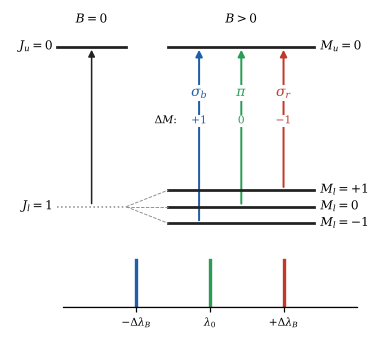

In [4]:
setup(base=8)
fig = plt.figure(figsize=(COLUNA, 2.9))
ax = fig.add_axes([0, 0.30, 1, 0.70]); axs = fig.add_axes([0.14, 0.07, 0.80, 0.17])
yu, yl, dE = 3.0, 0.6, 0.25
ax.plot([0.15, 1.05], [yu, yu], color=CORES['I'], lw=1.8); ax.plot([0.15, 1.05], [yl, yl], color=CORES['cinza'], lw=1, ls=':')
ax.text(0.6, 3.35, '$B = 0$', ha='center'); ax.text(2.55, 3.35, '$B > 0$', ha='center')
ax.text(0.1, yu, '$J_u = 0$', ha='right', va='center'); ax.text(0.1, yl, '$J_l = 1$', ha='right', va='center')
ax.add_patch(FancyArrowPatch((0.6, yl), (0.6, yu), arrowstyle='-|>', mutation_scale=9, color=CORES['I'], lw=1))
ax.plot([1.6, 3.5], [yu, yu], color=CORES['I'], lw=1.8); ax.text(3.58, yu, '$M_u = 0$', va='center')
for M in (-1, 0, 1):
    y = yl + M*dE
    ax.plot([1.6, 3.5], [y, y], color=CORES['I'], lw=1.8); ax.text(3.58, y, f'$M_l = {M:+d}$'.replace('+0', '0'), va='center')
    ax.plot([1.05, 1.6], [yl, y], color=CORES['cinza'], lw=0.6, ls='--')
comp = [(2.0, -1, '$\sigma_b$', '$+1$', CORES['Q']), (2.55, 0, '$\pi$', '$0$', CORES['U']), (3.1, 1, '$\sigma_r$', '$-1$', CORES['V'])]
ax.text(1.72, 1.85, '$\Delta M$:', ha='right', fontsize=7)
for x, M, nome, dm, col in comp:
    ax.add_patch(FancyArrowPatch((x, yl + M*dE), (x, yu), arrowstyle='-|>', mutation_scale=9, color=col, lw=1.3))
    ax.text(x, 2.25, nome, ha='center', color=col, fontsize=9, bbox=dict(fc='white', ec='none', pad=0.5))
    ax.text(x, 1.85, dm, ha='center', color=col, fontsize=7, bbox=dict(fc='white', ec='none', pad=0.5))
ax.set_xlim(-0.45, 4.35); ax.set_ylim(0.2, 3.55); ax.axis('off')
x = np.linspace(-2, 2, 5)
for xc, col in [(-1, CORES['Q']), (0, CORES['U']), (1, CORES['V'])]:
    axs.plot([xc, xc], [0, 1], color=col, lw=2.2)
axs.axhline(0, color=CORES['I'], lw=0.8); axs.set_xlim(-2, 2); axs.set_ylim(0, 1.15); axs.set_yticks([])
axs.set_xticks([-1, 0, 1]); axs.set_xticklabels(['$-\Delta\lambda_B$', '$\lambda_0$', '$+\Delta\lambda_B$'])
for s in ('left', 'top', 'right'): axs.spines[s].set_visible(False)
salvar(fig, 'fig2_zeeman')
setup()

## 3. Parâmetros de referência de Milne-Eddington (Fe I 630,25 nm)

In [5]:
L = sp.LINHAS['Fe I 630,25 nm']; lam0, g = L['lam0'], L['g']
dl = np.linspace(-0.45, 0.45, 901); lam = lam0 + dl
base = dict(vlos=0.0, dlD=sp.doppler_width(lam0, 6000, 1.0), eta0=10.0, a=0.15, S0=0.3, S1=0.7)
print({k: round(v, 4) for k, v in base.items()})
def sint(B, gamma, chi=0.0, **kw):
    p = dict(base); p.update(kw)
    return sp.me_synthesis(lam, lam0, g, B, np.deg2rad(gamma), np.deg2rad(chi), **p)
S = sint(0, 0); print('contínuo I(±0,45 Å) =', S[0, [0, -1]].round(4), '; Q,U,V máximos para B=0:', np.abs(S[1:]).max())

{'vlos': 0.0, 'dlD': np.float64(0.0351), 'eta0': 10.0, 'a': 0.15, 'S0': 0.3, 'S1': 0.7}
contínuo I(±0,45 Å) = [0.9964 0.9964] ; Q,U,V máximos para B=0: 0.0


## 4. Figura S4 — Perfis de Stokes nas três geometrias ($B = 1000$ G, material suplementar)

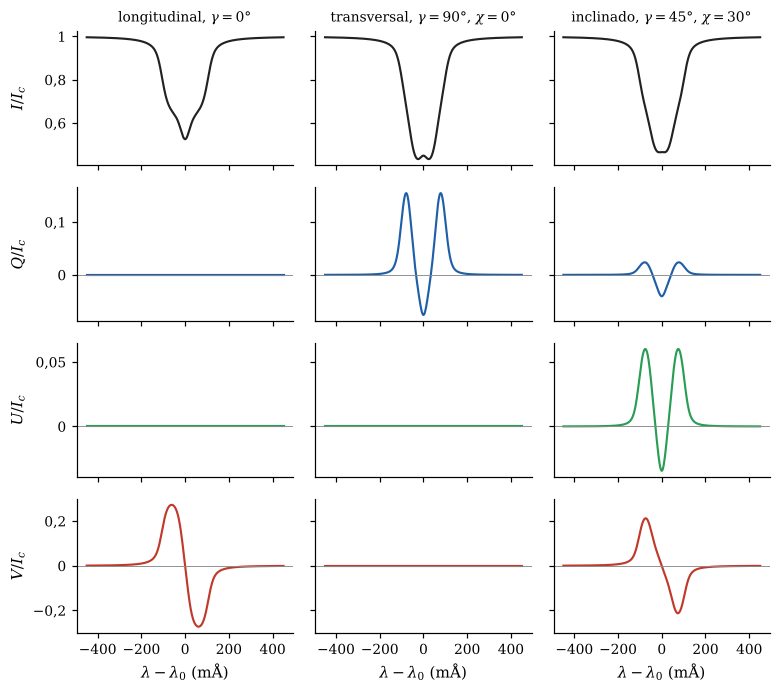

In [6]:
casos = [('longitudinal, $\\gamma = 0°$', 0, 0), ('transversal, $\\gamma = 90°$, $\\chi = 0°$', 90, 0), ('inclinado, $\\gamma = 45°$, $\\chi = 30°$', 45, 30)]
fig, axs = plt.subplots(4, 3, figsize=(7.2, 6.4), sharex=True, sharey='row')
x = dl * 1e3
for j, (tit, gam, chi) in enumerate(casos):
    S = sint(1000, gam, chi)
    for i, nome in enumerate('IQUV'):
        ax = axs[i, j]
        ax.plot(x, S[i], color=CORES[nome])
        if i: ax.axhline(0, color=CORES['cinza'], lw=0.6)
        if j == 0: ax.set_ylabel(f'${nome}/I_c$')
        virgula(ax, 'y')
    axs[0, j].set_title(tit, fontsize=9)
    axs[3, j].set_xlabel('$\\lambda - \\lambda_0$ (mÅ)')
fig.align_ylabels(axs[:, 0]); fig.tight_layout()
salvar(fig, 'figS4_perfis_geometria')

## 5. Figura 3 do artigo — Assinaturas de campo longitudinal e transversal

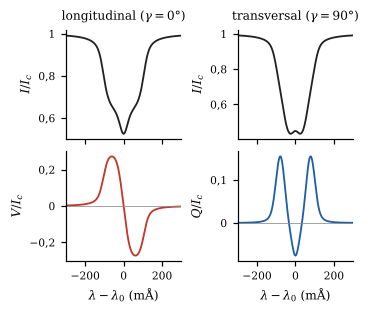

In [7]:
setup(base=8)
fig, axs = plt.subplots(2, 2, figsize=(COLUNA, 2.9), sharex=True)
for j, (tit, gam, k, nome) in enumerate([('longitudinal ($\\gamma = 0°$)', 0, 3, 'V'), ('transversal ($\\gamma = 90°$)', 90, 1, 'Q')]):
    S = sint(1000, gam, 0)
    axs[0, j].plot(x, S[0], color=CORES['I']); axs[0, j].set_title(tit)
    axs[1, j].plot(x, S[k], color=CORES[nome]); axs[1, j].axhline(0, color=CORES['cinza'], lw=0.5)
    axs[1, j].set_ylabel(f'${nome}/I_c$'); axs[1, j].set_xlabel('$\\lambda - \\lambda_0$ (mÅ)')
    for i in range(2): virgula(axs[i, j], 'y')
    axs[1, j].set_xlim(-300, 300); axs[1, j].set_xticks([-200, 0, 200])
axs[0, 0].set_ylabel('$I/I_c$'); axs[0, 1].set_ylabel('$I/I_c$')
fig.tight_layout(w_pad=0.8, h_pad=0.6)
salvar(fig, 'fig3_perfis')
setup()

## 6. Figura S5 — Efeito de cada parâmetro sobre $I$ e $V$ (referência: $B = 500$ G, $\gamma = 30°$)

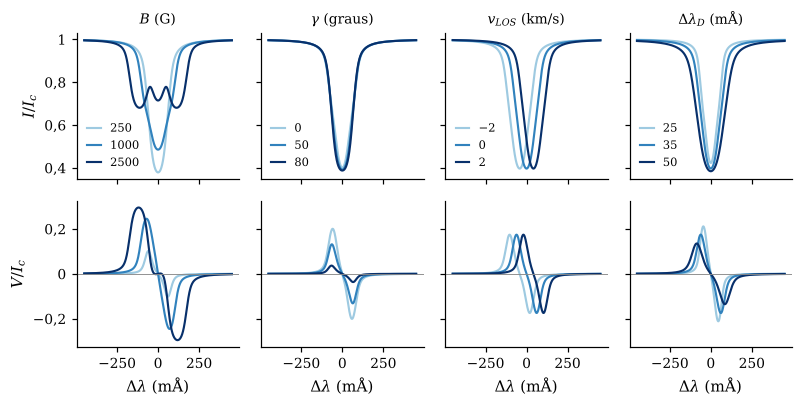

In [8]:
tons = ['#9ecae1', '#3182bd', '#08306b']
vari = [('$B$ (G)', 'B', [250, 1000, 2500]),
        ('$\\gamma$ (graus)', 'gamma', [0, 50, 80]),
        ('$v_{LOS}$ (km/s)', 'vlos', [-2, 0, 2]),
        ('$\\Delta\\lambda_D$ (mÅ)', 'dlD', [25, 35, 50])]
fig, axs = plt.subplots(2, 4, figsize=(7.4, 3.8), sharex=True, sharey='row')
for j, (tit, chave, vals) in enumerate(vari):
    for v, cor in zip(vals, tons):
        p = dict(B=500, gamma=30)
        if chave in ('B', 'gamma'): p[chave] = v; kw = {}
        elif chave == 'dlD': kw = {'dlD': v/1e3}
        else: kw = {chave: v}
        S = sint(p['B'], p['gamma'], **kw)
        rot = f'{v:g}'.replace('.', ',').replace('-', '−')
        axs[0, j].plot(x, S[0], color=cor, label=rot); axs[1, j].plot(x, S[3], color=cor)
    axs[0, j].set_title(tit, fontsize=9); axs[0, j].legend(frameon=False, fontsize=7.5, loc='lower left', handlelength=1.2)
    axs[1, j].axhline(0, color=CORES['cinza'], lw=0.6); axs[1, j].set_xlabel('$\\Delta\\lambda$ (mÅ)')
    for i in range(2): virgula(axs[i, j], 'y')
axs[0, 0].set_ylabel('$I/I_c$'); axs[1, 0].set_ylabel('$V/I_c$')
fig.tight_layout()
salvar(fig, 'figS5_parametros_me')

## Exercícios

1. Compare os perfis de Fe I 630,25 nm e Fe I 630,15 nm para o mesmo campo (exercício 2 da Seção S7 do material suplementar).
2. Desligue os efeitos magneto-ópticos (zere os $\rho$ em `propagation_matrix`) e observe a mudança em $Q$ e $U$ para campos fortes.
3. Verifique que $Q \propto \cos 2\chi$ e $U \propto \sin 2\chi$ variando $\chi$ com campo transversal.